# Notebook 04 - models, tuning and the feature ablation
Three models of increasing complexity, tuned without leakage, plus an ablation that measures what each feature group from notebook 03 is actually worth. Reads `data/model_table.csv.gz`; writes the chosen feature set and tuned parameters to `results/model_config.json` for notebooks 05-07.

1. **Physics baseline** - linear regression with a per-compound intercept and tyre-age slope plus a single fuel slope, following Heilmeier's lap-time decomposition (lap time = base + tyre wear + fuel mass). Fully interpretable, and it only ever uses `tyre_age`, `fuel_proxy` and `compound`.
2. **XGBoost** - gradient boosting on the full feature set, the community-standard model for tabular data and what the F1 StratLab benchmark uses. Trees handle non-linear effects (tyre cliffs, traffic) and missing values natively, and don't need feature scaling.
3. **Residual model** - XGBoost trained on the physics baseline's residuals. The bet: physical relationships (fuel burn, tyre wear) should transfer across the regulation change better than raw learned patterns.

**Rules we hold to:**
- Never split laps randomly. Laps from one race are highly correlated (same cars, same track, same day), so every split is by race or by season.
- **Tuning and feature selection only ever see 2022-2024.** 2025 (our in-era test) and 2026 (the regime shift) never influence a single choice made here. Picking the feature set that happened to do best on 2026 would be test-set leakage.

In [1]:
import os, sys
# Run from the repo root so data/, figures/ and results/ resolve, and make src/ importable.
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.path.abspath('src'))

import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, GridSearchCV
from f1lap.features import encode_features, FEATURE_GROUPS
from f1lap.models import SEED, make_xgb, metrics, evaluate_split, CONFIG_PATH

np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
os.makedirs('results', exist_ok=True)
df = pd.read_csv('data/model_table.csv.gz')
y = df['lap_delta_s']
race_id = pd.factorize(df['season'].astype(str) + '_' + df['event'])[0]
tune = (df.season <= 2024).to_numpy()
print('Model table:', df.shape, '| tuning laps (2022-2024):', tune.sum())

Model table: (90488, 57) | tuning laps (2022-2024): 53084


### 1. Feature ablation with per-set tuning
We add the feature groups one at a time, then also try the full set **without the team one-hot columns**. That last one is the cleanest test of our central idea: a model that is never told *which* car it is, only how fast that car has been *measured* to be.

Each set gets its own hyperparameter search, so no set is handicapped by parameters tuned for another. The search is a 54-point grid scored by **GroupKFold (5 folds) grouped by race** on 2022-2024. The grid is wider than in our first iteration, because last time the best parameters sat at the edge of the grid (shallowest trees, slowest learning rate), which usually means the true optimum lies outside it.

In [2]:
SETS = {
    'base (team names)':   (['base'], True),
    '+ qualifying':        (['base', 'quali'], True),
    '+ driver':            (['base', 'quali', 'driver'], True),
    '+ in-race':           (['base', 'quali', 'driver', 'race'], True),
    '+ circuit':           (['base', 'quali', 'driver', 'race', 'circuit'], True),
    '+ weather (all)':     (list(FEATURE_GROUPS), True),
    'all, no team names':  (list(FEATURE_GROUPS), False),
}
GRID = {'max_depth': [3, 5, 7], 'learning_rate': [0.01, 0.03, 0.1],
        'n_estimators': [150, 400, 1000], 'min_child_weight': [10, 50]}
te25 = (df.season == 2025).to_numpy()
rows, searches, t0 = [], {}, time.time()
for name, (groups, team) in SETS.items():
    X = encode_features(df, groups, team)
    s = GridSearchCV(make_xgb(n_jobs=1), GRID, scoring='neg_mean_absolute_error',
                     cv=GroupKFold(n_splits=5), n_jobs=-1)
    s.fit(X[tune], y[tune].values, groups=race_id[tune])
    searches[name] = s
    pred25 = make_xgb(**s.best_params_).fit(X[tune], y[tune].values).predict(X[te25])
    rows.append({'feature set': name, 'features': X.shape[1], 'CV MAE': -s.best_score_,
                 'CV sd': s.cv_results_['std_test_score'][s.best_index_],
                 '2025 test MAE': metrics(y[te25], pred25)['MAE'], **s.best_params_})
abl = pd.DataFrame(rows).set_index('feature set')
print(f'{len(SETS)} feature sets x {len(s.cv_results_["params"])} grid points x 5 folds in {time.time() - t0:.0f}s')
abl.round(4)

7 feature sets x 54 grid points x 5 folds in 519s


,features,CV MAE,CV sd,2025 test MAE,learning_rate,max_depth,min_child_weight,n_estimators
feature set,,,,,,,,
base (team names),20,0.5953,0.0317,0.5891,0.03,3,50,150
+ qualifying,25,0.5939,0.0310,0.5835,0.03,3,50,150
+ driver,26,0.5950,0.0323,0.5805,0.01,3,50,1000
+ in-race,32,0.5153,0.0395,0.4921,0.03,5,50,150
+ circuit,36,0.4983,0.0412,0.4734,0.01,5,50,1000
+ weather (all),39,0.4978,0.0387,0.4692,0.01,5,50,1000
"all, no team names",28,0.4999,0.0387,0.4686,0.01,5,50,1000


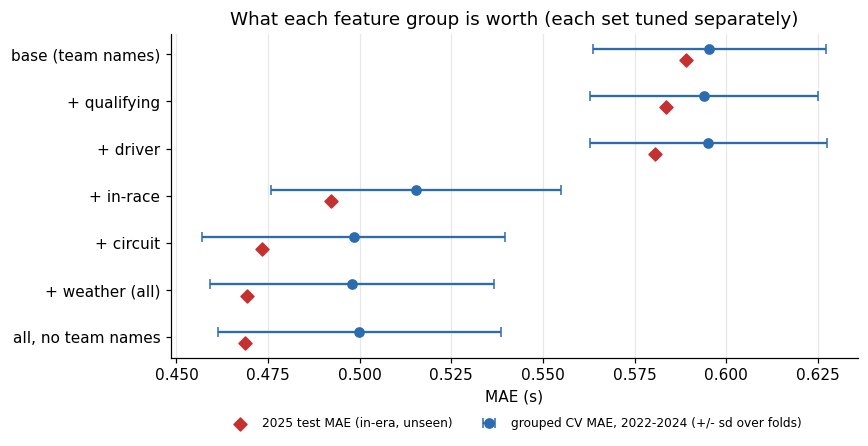

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.2))
yy = np.arange(len(abl))[::-1]
ax.errorbar(abl['CV MAE'], yy + 0.12, xerr=abl['CV sd'], fmt='o', color='#2b6cb0', capsize=3,
            label='grouped CV MAE, 2022-2024 (+/- sd over folds)')
ax.scatter(abl['2025 test MAE'], yy - 0.12, marker='D', color='#c53030', zorder=3, label='2025 test MAE (in-era, unseen)')
ax.set_yticks(yy); ax.set_yticklabels(abl.index); ax.set_xlabel('MAE (s)'); ax.grid(axis='x', alpha=.3)
ax.set_title('What each feature group is worth (each set tuned separately)')
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.tight_layout(); plt.savefig('figures/11_feature_ablation.png', dpi=150); plt.show()

**Figure 11.** Four things stand out:
1. **The in-race group is where the in-era gains are.** Adding gaps, recent pace, stint lap and positions gained drops CV MAE from 0.595 to 0.515 s (-13%), and the unseen 2025 error from 0.581 to 0.492 s. How a driver has been lapping over the last few laps, and whether they're stuck behind someone, is most of what separates a good lap prediction from a mediocre one.
2. **Qualifying and driver features barely move the in-era numbers** (0.595 -> 0.594). That's not because they carry no information (notebook 03 showed qualifying pace correlates strongly with race pace). It's because within a stable era the team columns already encode most of the same car-pace information. Their real test is 2026, when team identity goes stale, which is notebook 05's job.
3. **Circuit features help more than their tiny correlations suggested** (0.515 -> 0.498). That's the signature of interactions: what traffic or tyre wear costs depends on the track. Weather adds essentially nothing on top.
4. **Dropping the team names costs nothing.** The full set *without* any team columns (28 features) scores 0.500 vs 0.498 with them, a difference 20 times smaller than the fold-to-fold spread, and it's marginally *better* on the unseen 2025 season. Once the model measures pace, being told the car's name is redundant. Notebook 05 tests whether that measurement-only model also degrades less in 2026.

**Selection rule, fixed before looking at any 2026 number:** the lowest grouped-CV MAE, which is the full set with team names.

### 2. How much does tuning matter?

In [4]:
FINAL = abl['CV MAE'].idxmin()
r = pd.DataFrame(searches[FINAL].cv_results_)
r['CV MAE'] = -r.mean_test_score
print(f'Chosen feature set: {FINAL!r} (lowest grouped-CV MAE)')
print(f'Best grid point:  {searches[FINAL].best_params_}')
print(f'CV MAE across the grid: best {r["CV MAE"].min():.4f}, median {r["CV MAE"].median():.4f}, worst {r["CV MAE"].max():.4f} s')
print(f'Fold-to-fold sd at the best point: {abl.loc[FINAL, "CV sd"]:.4f} s')
r.sort_values('CV MAE')[['param_max_depth', 'param_learning_rate', 'param_n_estimators', 'param_min_child_weight', 'CV MAE']].head(8).round(4)

Chosen feature set: '+ weather (all)' (lowest grouped-CV MAE)
Best grid point:  {'learning_rate': 0.01, 'max_depth': 5, 'min_child_weight': 50, 'n_estimators': 1000}
CV MAE across the grid: best 0.4978, median 0.5106, worst 0.6046 s
Fold-to-fold sd at the best point: 0.0387 s


,param_max_depth,param_learning_rate,param_n_estimators,param_min_child_weight,CV MAE
11,5,0.01,1000,50,0.4978
27,5,0.03,150,50,0.4980
28,5,0.03,400,50,0.4986
33,7,0.03,150,50,0.4987
16,7,0.01,400,50,0.4991
22,3,0.03,400,50,0.4992
24,5,0.03,150,10,0.4996
8,5,0.01,1000,10,0.4997


**The optimum is a flat plateau.** The top 8 grid points sit within ~0.002 s of each other, about 20 times smaller than the fold-to-fold spread (~0.039 s). The best point (learning rate 0.01, 1000 trees) looks like it's on a grid edge, but the runner-up (0.03, 150 trees) scores the same: what matters is the total amount of learning (learning rate x trees), not either one alone. The one consistent signal is that `min_child_weight` = 50, the more regularised option, wins in *every* feature set, and 50 is the top of the grid. So we push past that edge below rather than assume.

In [5]:
p = {k: [v] for k, v in searches[FINAL].best_params_.items()}
p['min_child_weight'] = [50, 100, 200, 400]
X_final = encode_features(df, *SETS[FINAL])
edge = GridSearchCV(make_xgb(n_jobs=1), p, scoring='neg_mean_absolute_error', cv=GroupKFold(n_splits=5), n_jobs=-1)
edge.fit(X_final[tune], y[tune].values, groups=race_id[tune])
final_params = edge.best_params_
pd.DataFrame({'min_child_weight': p['min_child_weight'], 'CV MAE': -edge.cv_results_['mean_test_score'],
              'CV sd': edge.cv_results_['std_test_score']}).round(4)

,min_child_weight,CV MAE,CV sd
0,50,0.4978,0.0387
1,100,0.4975,0.0382
2,200,0.4967,0.0381
3,400,0.4967,0.0380


Going past the edge buys about 0.001 s, again far inside the noise, so the edge was not hiding a better model. We still adopt the best value from this extended check, so the saved parameters are the true optimum of everything we searched.

### 3. Save the final configuration

In [6]:
groups, team = SETS[FINAL]
cfg = {'name': FINAL, 'groups': groups, 'team': team, 'xgb_params': final_params}
json.dump(cfg, open(CONFIG_PATH, 'w'), indent=1)
print(json.dumps(cfg, indent=1))

{
 "name": "+ weather (all)",
 "groups": [
  "base",
  "quali",
  "driver",
  "race",
  "circuit",
  "weather"
 ],
 "team": true,
 "xgb_params": {
  "learning_rate": 0.01,
  "max_depth": 5,
  "min_child_weight": 400,
  "n_estimators": 1000
 }
}


### 4. In-era check: all three models on the final features (train 2022-2024, test 2025)

In [7]:
X_all = encode_features(df, groups, team)
inera = evaluate_split(df, X_all, y, df.season <= 2024, df.season == 2025, cfg['xgb_params']).round(3)
print('In-era (train 2022-2024, test 2025), MAE/RMSE in seconds:')
inera

In-era (train 2022-2024, test 2025), MAE/RMSE in seconds:


,MAE,RMSE
Physics,0.762,1.008
XGBoost,0.473,0.665
Residual,0.464,0.659


**Read:** on the unseen 2025 season the final XGBoost lands at **0.473 s** and the residual model at **0.464 s**, down from ~0.586 s with the original features, about **-20%**. (The XGBoost number is 0.004 s worse than it was with `min_child_weight` = 50, a good reminder that differences this small are noise.) RMSE is ~40% above MAE, so errors still have a tail: most laps are predicted well and a minority are missed by a lot. The physics baseline is unchanged at 0.76 s, since it only ever uses tyre age, fuel and compound.

Against the **F1 StratLab** benchmark (~0.39 s MAE) we're now in the same ballpark, but it's a loose comparison: they predict raw lap times on 2023-2025, while we predict the race-median-relative delta and hold out a whole season. This ~0.47 s is the in-era bar for the regime shift in notebook 05.